# E-Commerce Sales & Customer Behavior Analysis
<p align="center">
  <img src="../reports/figures/ecommerce_warehouse_operations.jpeg" alt="E-Commerce Operations" width="85%"/>
</p>
**Dataset:** UCI Online Retail Dataset (Transactions from 01/12/2010 to 09/12/2011)  
**Author:** Portfolio Project  

### 1. Project Overview & Business Objectives
An online retail company registered in the UK specializes in unique all-occasion gifts. Many customers are wholesalers. This project applies comprehensive Exploratory Data Analysis (EDA) to understand:
- Revenue drivers and top product lines
- Regional demand across international markets
- Seasonality and order velocity
- Customer transaction behaviors, order values, and cancellation patterns

---
### 2. Environment Setup & Data Loading

In [1]:
# Standard Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuration
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style='whitegrid', palette='muted')

# File path (adjust extension if you converted it to .csv)
data_path = '../data/raw/Online Retail.xlsx'

try:
    df = pd.read_excel(data_path)
    print("Dataset loaded successfully via Excel engine.")
except Exception as e:
    # Fallback if saved as CSV
    df = pd.read_csv('../data/raw/Online_Retail.csv', encoding='ISO-8859-1')
    print("Dataset loaded successfully via CSV fallback.")

# Initial Inspection
print(f"Shape: {df.shape[0]:,} rows | {df.shape[1]} columns\n")
df.info()

Dataset loaded successfully via Excel engine.
Shape: 541,909 rows | 8 columns

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [2]:
# Preview first 5 transactions
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom


### 3. Data Quality Audit & Diagnostic Profiling
Before altering the dataset, we conduct an audit across four vectors:
1. **Missing values** across all columns.
2. **Duplicate transactions**.
3. **Domain anomalies:** Negative/zero values in `Quantity` and `UnitPrice`, along with cancellation markers in `InvoiceNo` (invoices starting with 'C').
4. **Summary statistics & Skewness:** Checking distributional properties of continuous numerical variables.

In [3]:
# 1. Missing Values Audit
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Pct (%)': (df.isnull().sum() / len(df)) * 100
})
print("--- MISSING VALUES SUMMARY ---")
print(missing_df[missing_df['Missing_Count'] > 0])
print("\n" + "="*50 + "\n")

# 2. Duplicate Records
num_duplicates = df.duplicated().sum()
print(f"Total Duplicate Rows: {num_duplicates:,} ({(num_duplicates / len(df)) * 100:.2f}%)")
print("\n" + "="*50 + "\n")

# 3. Anomaly & Negative Value Inspection
df['InvoiceNo_Str'] = df['InvoiceNo'].astype(str)
cancelled_invoices = df[df['InvoiceNo_Str'].str.startswith('C')]
negative_qty = df[df['Quantity'] <= 0]
zero_or_negative_price = df[df['UnitPrice'] <= 0]

print("--- ANOMALY COUNTS ---")
print(f"Invoices marked as Cancelled ('C'): {len(cancelled_invoices):,}")
print(f"Transactions with Quantity <= 0: {len(negative_qty):,}")
print(f"Transactions with UnitPrice <= 0: {len(zero_or_negative_price):,}")
print("\n" + "="*50 + "\n")

# 4. Statistical Distributions & Skewness
num_cols = ['Quantity', 'UnitPrice']
summary_stats = df[num_cols].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
skewness = df[num_cols].skew()

print("--- DESCRIPTIVE STATISTICS ---")
print(summary_stats)
print("\n--- SKEWNESS COEFFICIENTS ---")
for col in num_cols:
    print(f"{col}: {skewness[col]:.2f}")

--- MISSING VALUES SUMMARY ---
             Missing_Count  Missing_Pct (%)
Description           1454             0.27
CustomerID          135080            24.93


Total Duplicate Rows: 5,268 (0.97%)


--- ANOMALY COUNTS ---
Invoices marked as Cancelled ('C'): 9,288
Transactions with Quantity <= 0: 10,624
Transactions with UnitPrice <= 0: 2,517


--- DESCRIPTIVE STATISTICS ---
       Quantity  UnitPrice
count 541909.00  541909.00
mean       9.55       4.61
std      218.08      96.76
min   -80995.00  -11062.06
1%        -2.00       0.19
5%         1.00       0.42
50%        3.00       2.08
95%       29.00       9.95
99%      100.00      18.00
max    80995.00   38970.00

--- SKEWNESS COEFFICIENTS ---
Quantity: -0.26
UnitPrice: 186.51


### Diagnostic Observations & Data Cleaning Decisions

#### Key Observations
1. **Missing Identifiers:**
   - `CustomerID` is missing in **135,080** records (24.93%). These represent guest checkouts or unregistered buyers. Imputing random or central IDs would distort customer behavior metrics.
   - `Description` is missing in **1,454** records (0.27%), which coincide with inventory errors and zero unit prices.
2. **Operational Duplicates:**
   - **5,268** duplicate rows (0.97%) were found, representing accidental double-logging or re-entry of the same cart item.
3. **Cancelled Orders & Negative Quantities:**
   - **9,288** invoices start with `'C'`, signifying official cancellations.
   - **10,624** rows exhibit `Quantity <= 0`. Some negative quantities reflect unlabelled stock write-offs (e.g., broken, lost stock) rather than customer returns.
4. **Price Anomalies & Extreme Outliers:**
   - **2,517** rows have `UnitPrice <= 0` (including a negative value of -11,062.06 and 0.00 entries for damaged/gift samples).
   - Extreme skewness in `UnitPrice` (186.51) confirms heavy distortion caused by administrative stock-adjustment lines (e.g., "AMAZON FEE", "Manual").

#### Data Cleaning Strategy
- **Step 1:** Remove the 5,268 duplicate transactions.
- **Step 2:** Isolate cancelled transactions into a separate subset (`df_cancelled`) for dedicated return-rate and churn analysis.
- **Step 3:** Filter the primary sales dataset (`df_clean`) to valid commercial transactions: `Quantity > 0` and `UnitPrice > 0`.
- **Step 4:** Remove non-product service/fee codes (e.g., `POST`, `D`, `DOT`, `M`, `BANK CHARGES`, `AMAZONFEE`).
- **Step 5:** Engineer core analytical features:
  - `TotalPrice` = `Quantity * UnitPrice`
  - `Year`, `Month`, `YearMonth`, `DayOfWeek`, `Hour` from `InvoiceDate`.
  - Flag whether transaction has an associated registered `CustomerID`.

### 3b. Categorical Profiling, Noise Detection & Unique Cardinality
To ensure cleaning criteria are evidence-based rather than arbitrary, we profile:
1. **Cardinality (`nunique`):** Unique orders, distinct SKUs, unique customers, and geographical reach.
2. **Administrative Stock Codes (Noise):** Non-numeric codes indicating postage, adjustments, fees, or system tests.
3. **Suspicious / Garbage Descriptions:** Lowercase notes or damage remarks that explain inventory adjustments.
4. **Geographic Concentration (`value_counts`):** Distribution of transactions across trading markets.

In [4]:
# 1. Cardinality (nunique)
cardinality_df = pd.DataFrame({
    'Column': df.columns,
    'Unique_Count': [df[col].nunique() for col in df.columns],
    'Data_Type': [df[col].dtype for col in df.columns]
})
print("--- COLUMN CARDINALITY (NUNIQUE) ---")
print(cardinality_df.to_string(index=False))
print("\n" + "="*60 + "\n")

# 2. Detecting Non-Product Stock Codes (Noise / Fees / System Artifacts)
# Regular items are typically 5-digit numbers (or 5 digits + a letter suffix)
non_numeric_stock = df[df['StockCode'].astype(str).str.contains(r'^[a-zA-Z]+$', regex=True)]
print("--- TOP ADMINISTRATIVE / NON-PRODUCT STOCK CODES ---")
print(non_numeric_stock['StockCode'].value_counts().head(10))
print("\n" + "="*60 + "\n")

# 3. Investigating Suspicious / Noise Descriptions
# Real gift items are uppercase. Lowercase descriptions often reveal warehouse comments.
lowercase_desc = df[df['Description'].astype(str).str.islower() & df['Description'].notnull()]
print(f"Total lowercase descriptions detected: {len(lowercase_desc):,}")
print("Sample lowercase administrative notes:")
print(lowercase_desc['Description'].value_counts().head(10))
print("\n" + "="*60 + "\n")

# 4. Top Country Value Counts (Market Concentration)
print("--- TOP 10 COUNTRIES BY TRANSACTION VOLUME ---")
country_counts = df['Country'].value_counts()
country_pct = (country_counts / len(df)) * 100
top_countries = pd.DataFrame({'Transactions': country_counts, 'Share (%)': country_pct})
print(top_countries.head(10))

--- COLUMN CARDINALITY (NUNIQUE) ---
       Column  Unique_Count      Data_Type
    InvoiceNo         25900         object
    StockCode          4070         object
  Description          4223         object
     Quantity           722          int64
  InvoiceDate         23260 datetime64[us]
    UnitPrice          1630        float64
   CustomerID          4372        float64
      Country            38            str
InvoiceNo_Str         25900            str


--- TOP ADMINISTRATIVE / NON-PRODUCT STOCK CODES ---
StockCode
POST         1256
DOT           710
M             571
D              77
S              63
AMAZONFEE      34
CRUK           16
DCGSSGIRL      13
DCGSSBOY       11
PADS            4
Name: count, dtype: int64


Total lowercase descriptions detected: 493
Sample lowercase administrative notes:
Description
check                    159
damages                   45
damaged                   43
found                     25
sold as set on dotcom     20
adjustment           

### 4. Findings from Cardinality & Noise Profiling

#### Key Findings
1. **Catalog Discrepancies:**
   - 4,070 unique `StockCode`s map to 4,223 unique `Description` entries. This mismatch highlights inconsistent labeling, typos, and administrative annotations for the same item.
2. **Administrative & Non-Product Transactions:**
   - Over 2,600 entries represent non-merchandise charges: `POST` (Postage: 1,256), `DOT` (Dotcom Postage: 710), `M` (Manual: 571), `D` (Discount: 77), `S` (Samples: 63), and `AMAZONFEE` (34). These must be excluded from product sales analysis.
3. **Internal Warehouse Logging:**
   - Identified 493 lowercase description records containing internal audit memos (`"check"`, `"damages"`, `"found"`, `"thrown away"`, `"adjustment"`). These are inventory adjustments rather than customer orders.
4. **Extreme Geographic Concentration:**
   - The UK dominates transactional volume with **91.43%** of all records. Non-UK markets represent a combined ~8.57% (led by Germany, France, and Ireland). Analysis will evaluate UK and international sales both aggregated and segmented.

#### Applied Cleaning Strategy
1. Deduplicate records.
2. Segregate cancelled orders (`InvoiceNo` starting with `'C'` or `Quantity < 0`) into a dedicated churn dataframe (`df_cancelled`).
3. Construct `df_clean` for positive sales (`Quantity > 0` and `UnitPrice > 0`).
4. Filter out administrative non-product codes (`POST`, `D`, `M`, `PADS`, `DOT`, `CRUK`, `BANK CHARGES`, `AMAZONFEE`, `S`).
5. Engineer core temporal and financial features (`TotalPrice`, `Year`, `Month`, `YearMonth`, `DayOfWeek`, `Hour`, `Has_CustomerID`).

In [5]:
# 1. Deduplication
initial_count = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_count - len(df):,} duplicate rows.")

# 2. Segregate Cancelled Orders for dedicated return analysis
df['Is_Cancelled'] = df['InvoiceNo_Str'].str.startswith('C')
df_cancelled = df[df['Is_Cancelled'] | (df['Quantity'] < 0)].copy()

# 3. Filter Valid Purchases: Positive Quantity and Positive UnitPrice
df_clean = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0) & (~df['Is_Cancelled'])].copy()

# 4. Filter Administrative & Service Stock Codes
service_stock_codes = ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK', 'BANK CHARGES', 'AMAZONFEE', 'S']
df_clean = df_clean[~df_clean['StockCode'].astype(str).str.upper().isin(service_stock_codes)]

# Standardize Description and handle remaining missing values
df_clean['Description'] = df_clean['Description'].fillna('Unknown').str.strip()

# 5. Feature Engineering
# Monetary value per line item
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Temporal features for time-series and behavioral seasonality
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

# Indicator for customer identity availability
df_clean['Has_CustomerID'] = df_clean['CustomerID'].notnull()

# 6. Post-Cleaning Audit & Summary
print(f"Cleaned Sales Dataset: {len(df_clean):,} records retained ({(len(df_clean) / initial_count) * 100:.2f}% of raw data)")
print(f"Isolated Cancellations/Adjustments: {len(df_cancelled):,} records")
print("\n--- SAMPLE CLEANED DATA ---")
print(df_clean[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'TotalPrice', 'Country', 'YearMonth']].head(5))
print("\n--- CLEANED METRIC DISTRIBUTIONS ---")
print(df_clean[['Quantity', 'UnitPrice', 'TotalPrice']].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]))

Removed 5,268 duplicate rows.
Cleaned Sales Dataset: 522,710 records retained (96.46% of raw data)
Isolated Cancellations/Adjustments: 10,587 records

--- SAMPLE CLEANED DATA ---
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

   UnitPrice  TotalPrice         Country YearMonth  
0       2.55       15.30  United Kingdom   2010-12  
1       3.39       20.34  United Kingdom   2010-12  
2       2.75       22.00  United Kingdom   2010-12  
3       3.39       20.34  United Kingdom   2010-12  
4       3.39       20.34  United Kingdom   2010-12  

--- CLEANED METRIC DISTRIBUTIONS ---
       Quantity  UnitPrice  Tota

### 5. Univariate Analysis: Numerical Distributions (Requirement: 3 Histograms)

#### Analytical Objective
We examine the individual distributions of our three fundamental commercial metrics:
1. **Quantity per transaction line item**
2. **Unit Price per item (£)**
3. **Total Spend per line item (`TotalPrice` in £)**

#### Distribution Insight Note
As demonstrated by our summary statistics, all three variables are heavily right-skewed with long tails driven by wholesale bulk purchases and institutional charges. To provide clear visualization without distortion from the top 1% extreme values, we plot histograms bounded at their respective 99th percentiles, overlaying KDE curves and median markers.

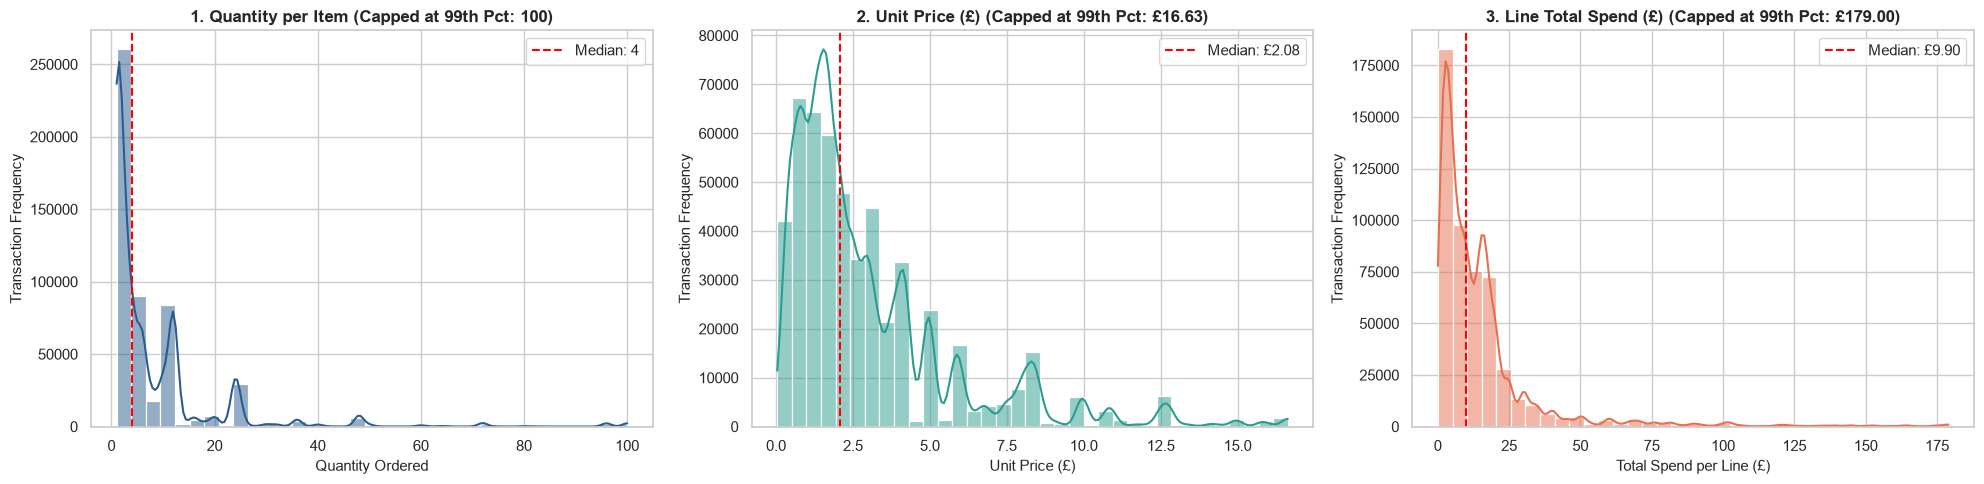

--- SUMMARY OF HISTOGRAM DISTRIBUTIONS ---
Quantity   | Median:   4.00 | 95th Pct:  30.00 | 99th Pct: 100.00
UnitPrice  | Median:   2.08 | 95th Pct:   9.95 | 99th Pct:  16.63
TotalPrice | Median:   9.90 | 95th Pct:  59.40 | 99th Pct: 179.00


In [6]:
# Setup 3-panel figure for the 3 required Histograms
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Histogram: Quantity (clipped to 99th percentile)
q_99 = df_clean['Quantity'].quantile(0.99)
sns.histplot(df_clean[df_clean['Quantity'] <= q_99]['Quantity'], 
             bins=35, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title(f'1. Quantity per Item (Capped at 99th Pct: {q_99:.0f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quantity Ordered', fontsize=11)
axes[0].set_ylabel('Transaction Frequency', fontsize=11)
axes[0].axvline(df_clean['Quantity'].median(), color='red', linestyle='--', label=f"Median: {df_clean['Quantity'].median():.0f}")
axes[0].legend()

# 2. Histogram: Unit Price (clipped to 99th percentile)
p_99 = df_clean['UnitPrice'].quantile(0.99)
sns.histplot(df_clean[df_clean['UnitPrice'] <= p_99]['UnitPrice'], 
             bins=35, kde=True, color='#2a9d8f', ax=axes[1])
axes[1].set_title(f'2. Unit Price (£) (Capped at 99th Pct: £{p_99:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Unit Price (£)', fontsize=11)
axes[1].set_ylabel('Transaction Frequency', fontsize=11)
axes[1].axvline(df_clean['UnitPrice'].median(), color='red', linestyle='--', label=f"Median: £{df_clean['UnitPrice'].median():.2f}")
axes[1].legend()

# 3. Histogram: Total Price per Line (clipped to 99th percentile)
t_99 = df_clean['TotalPrice'].quantile(0.99)
sns.histplot(df_clean[df_clean['TotalPrice'] <= t_99]['TotalPrice'], 
             bins=35, kde=True, color='#e76f51', ax=axes[2])
axes[2].set_title(f'3. Line Total Spend (£) (Capped at 99th Pct: £{t_99:.2f})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Total Spend per Line (£)', fontsize=11)
axes[2].set_ylabel('Transaction Frequency', fontsize=11)
axes[2].axvline(df_clean['TotalPrice'].median(), color='red', linestyle='--', label=f"Median: £{df_clean['TotalPrice'].median():.2f}")
axes[2].legend()

plt.tight_layout()
plt.savefig('../reports/figures/01_univariate_histograms.png', dpi=300, bbox_inches='tight')
plt.show()

# Print skewness and key percentile summary
print("--- SUMMARY OF HISTOGRAM DISTRIBUTIONS ---")
for col in ['Quantity', 'UnitPrice', 'TotalPrice']:
    median_val = df_clean[col].median()
    p95_val = df_clean[col].quantile(0.95)
    p99_val = df_clean[col].quantile(0.99)
    print(f"{col:10s} | Median: {median_val:6.2f} | 95th Pct: {p95_val:6.2f} | 99th Pct: {p99_val:6.2f}")

### 6. Univariate & Bivariate Outlier Profiling (Requirement: 3 Box Plots)

#### Observations from Histograms
1. **Packaging Multiples:** The Quantity distribution displays clear modal spikes at wholesale multi-pack sizes (6, 12, 24, and 36 units) rather than a smooth decay curve.
2. **Budget-Oriented Catalog:** The inventory is predominantly low-cost novelty/gift items, with a median unit price of £2.08 and 95% of items priced under £10.
3. **Transaction Micro-Slices:** Line-item spend clusters under £15, with a median of £9.90. High overall order totals are driven by basket depth (number of unique SKUs per order) rather than high standalone item prices.

---

#### Box Plot Investigation Design
To inspect variance, spreads, and the severity of outliers, we construct three distinct box plots:
- **Plot 1: `Quantity` by Top 5 Non-UK International Markets:** Assesses if foreign wholesale accounts order in significantly higher bulk quantities compared to domestic buyers.
- **Plot 2: `TotalPrice` by Day of the Week:** Determines whether transaction basket sizes experience weekend vs. weekday purchasing surges.
- **Plot 3: `UnitPrice` across Customer Type (Registered vs. Unregistered/Guest):** Evaluates whether guest checkouts purchase systematically higher or lower-priced items compared to registered accounts.

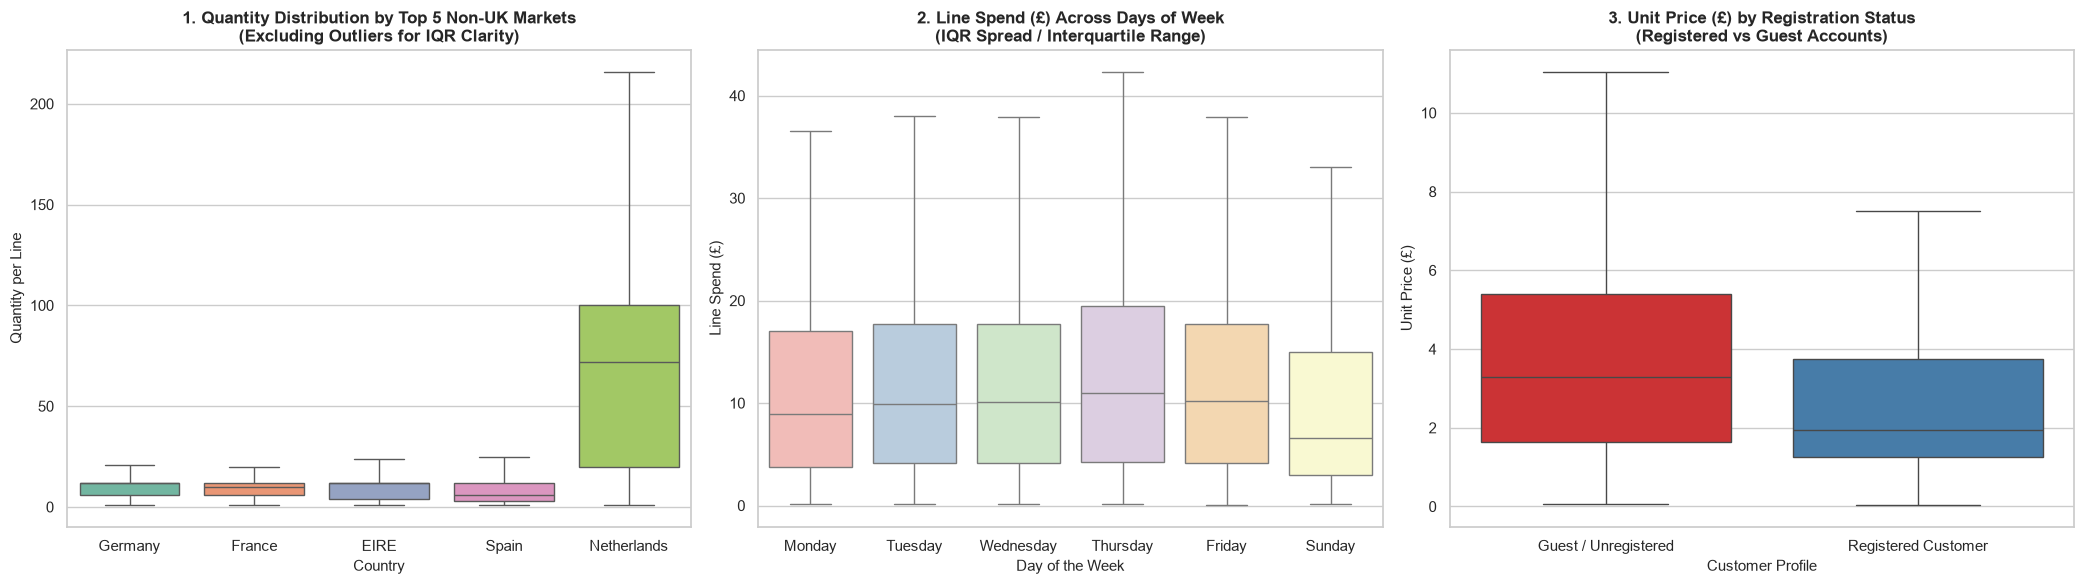

--- MEDIANS ACROSS KEY SEGMENTS ---
Median Quantity across Top 5 Non-UK Markets:
Country
EIRE          12.00
France        10.00
Germany       12.00
Netherlands   72.00
Spain          6.00
Name: Quantity, dtype: float64

Median Line Spend (£) by Day of Week:
DayOfWeek
Monday       8.94
Tuesday      9.90
Wednesday   10.08
Thursday    10.95
Friday      10.20
Sunday       6.60
Name: TotalPrice, dtype: float64

Median Unit Price by Registration Status:
Has_CustomerID
Guest        3.29
Registered   1.95
Name: UnitPrice, dtype: float64


In [7]:
# Setup 3-panel figure for Box Plots
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Box Plot: Quantity ordered across Top 5 Non-UK Countries
top_foreign_countries = ['Germany', 'France', 'EIRE', 'Spain', 'Netherlands']
df_foreign = df_clean[df_clean['Country'].isin(top_foreign_countries)]

# Using log scale / quantile cap to visually discern the IQR while showing outlier spread
sns.boxplot(data=df_foreign, x='Country', y='Quantity', palette='Set2', 
            order=top_foreign_countries, ax=axes[0], showfliers=False)
axes[0].set_title('1. Quantity Distribution by Top 5 Non-UK Markets\n(Excluding Outliers for IQR Clarity)', 
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Country', fontsize=11)
axes[0].set_ylabel('Quantity per Line', fontsize=11)

# 2. Box Plot: Total Spend per line across Days of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'] # Note: Saturday has no records in this dataset
sns.boxplot(data=df_clean, x='DayOfWeek', y='TotalPrice', palette='Pastel1',
            order=day_order, ax=axes[1], showfliers=False)
axes[1].set_title('2. Line Spend (£) Across Days of Week\n(IQR Spread / Interquartile Range)', 
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of the Week', fontsize=11)
axes[1].set_ylabel('Line Spend (£)', fontsize=11)

# 3. Box Plot: Unit Price by Customer Registration Status (Registered vs Guest)
sns.boxplot(data=df_clean, x='Has_CustomerID', y='UnitPrice', palette='Set1',
            ax=axes[2], showfliers=False)
axes[2].set_title('3. Unit Price (£) by Registration Status\n(Registered vs Guest Accounts)', 
                  fontsize=12, fontweight='bold')
axes[2].set_xticklabels(['Guest / Unregistered', 'Registered Customer'])
axes[2].set_xlabel('Customer Profile', fontsize=11)
axes[2].set_ylabel('Unit Price (£)', fontsize=11)

plt.tight_layout()
plt.savefig('../reports/figures/02_univariate_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

# Print IQR and Median metrics for the plotted segments
print("--- MEDIANS ACROSS KEY SEGMENTS ---")
print("Median Quantity across Top 5 Non-UK Markets:")
print(df_foreign.groupby('Country')['Quantity'].median())
print("\nMedian Line Spend (£) by Day of Week:")
print(df_clean.groupby('DayOfWeek')['TotalPrice'].median().reindex(day_order))
print("\nMedian Unit Price by Registration Status:")
print(df_clean.groupby('Has_CustomerID')['UnitPrice'].median().rename(index={False: 'Guest', True: 'Registered'}))

### 7. Categorical & Operational Analysis (Requirement: 3 Bar Charts & 2 Count Plots)

#### Observations from Box Plots
1. **B2B Concentration in the Netherlands:** The Netherlands demonstrates an exceptionally high median order volume of **72 units per line item** (compared to 6–12 for other European nations), revealing an enterprise wholesale footprint.
2. **Weekly Workflow & Saturday Closure:** Spending density peaks mid-week on Thursdays (£10.95 line median). The absence of Saturday transactions confirms an operational five-to-six-day dispatch schedule.
3. **Account Segmentation Pricing:** Guest checkouts exhibit a 68% higher median unit price (£3.29 vs. £1.95), indicating casual retail buyers purchase higher-margin individual gifts, whereas registered buyers order low-cost bulk items.

---

#### Categorical & Operational Visualizations
To evaluate commercial drivers and demand scheduling, we construct:
- **Bar Chart 1:** Top 10 Products by Total Revenue (£)
- **Bar Chart 2:** Top 10 Products by Total Units Sold
- **Bar Chart 3:** Top 10 Non-UK International Markets by Revenue (£)
- **Count Plot 1:** Transaction Frequency by Day of Week
- **Count Plot 2:** Hourly Order Distribution (Daily peak shopping window)

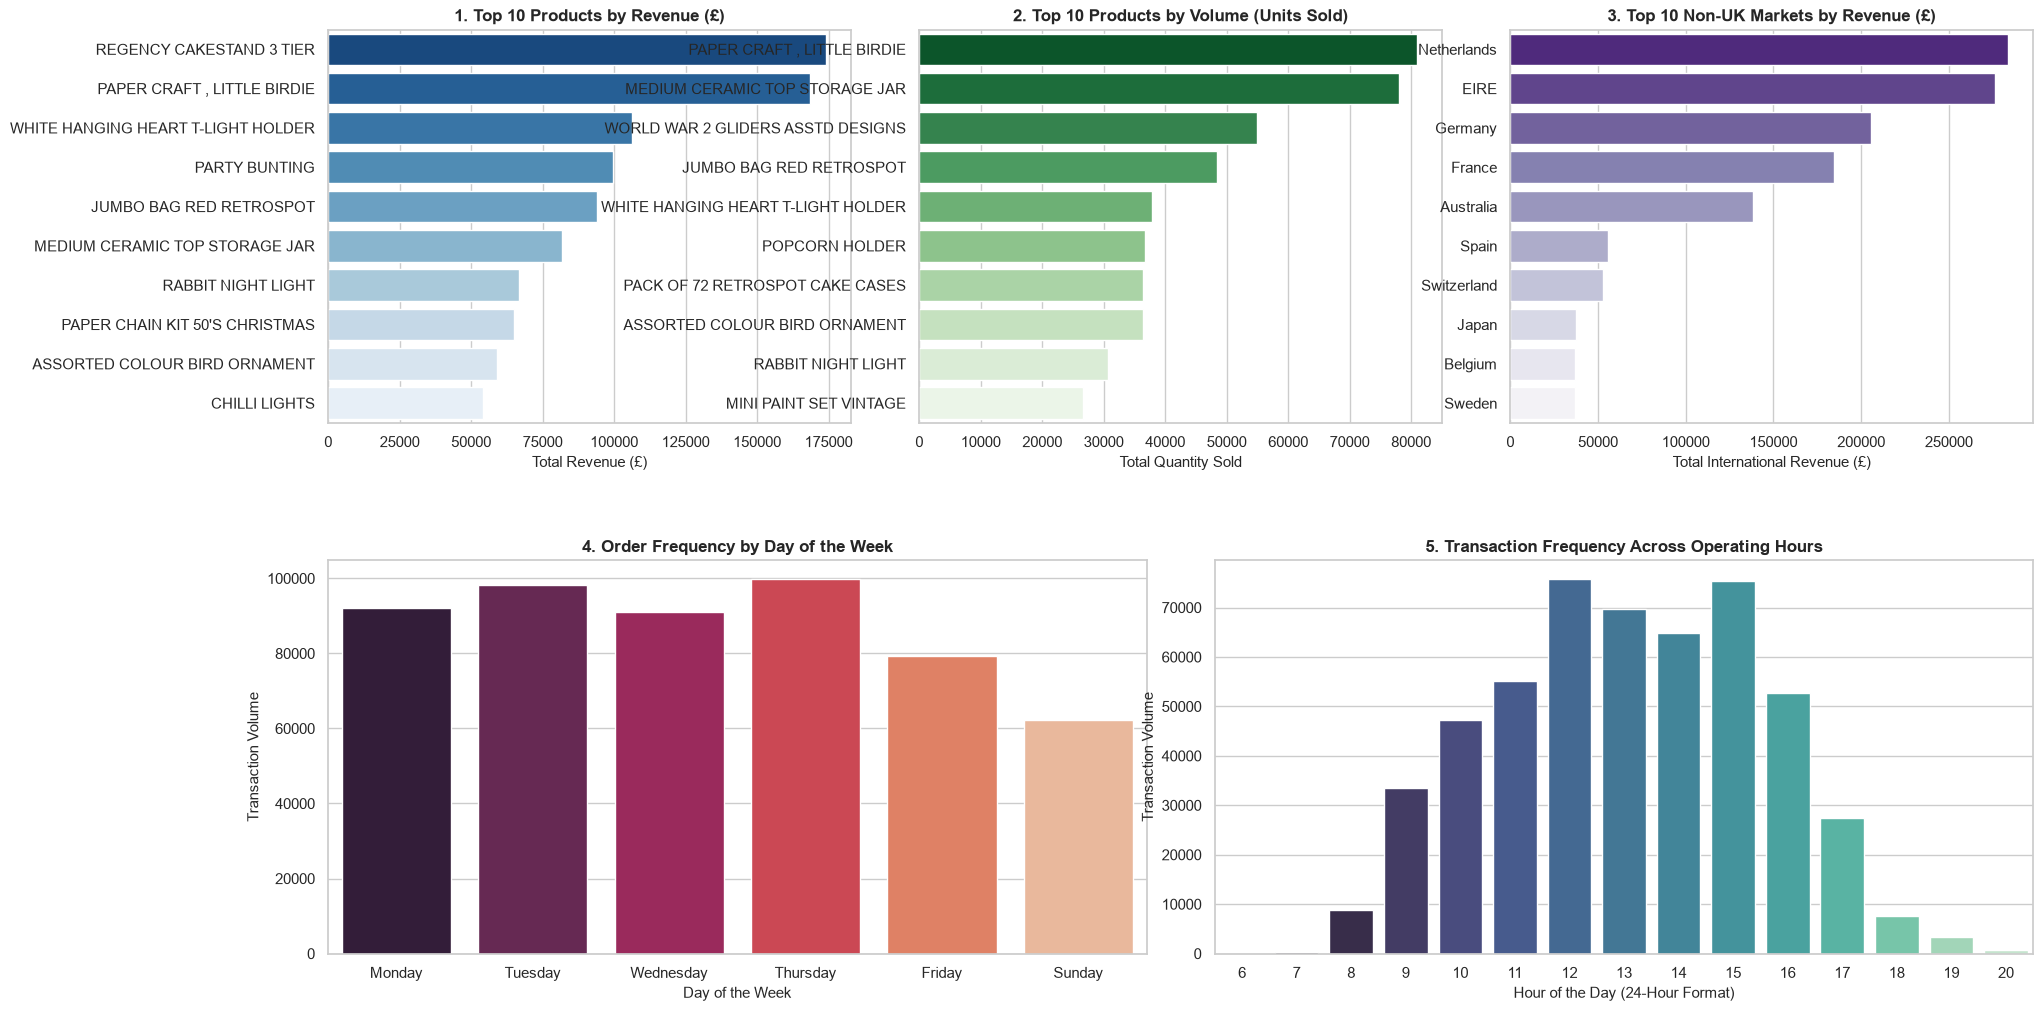

--- TOP 3 PRODUCTS BY REVENUE ---
Description
REGENCY CAKESTAND 3 TIER             174156.54
PAPER CRAFT , LITTLE BIRDIE          168469.60
WHITE HANGING HEART T-LIGHT HOLDER   106236.72
Name: TotalPrice, dtype: float64

--- TOP 3 NON-UK MARKETS BY REVENUE ---
Country
Netherlands   283889.34
EIRE          276090.86
Germany       205381.15
Name: TotalPrice, dtype: float64

--- PEAK HOURLY VOLUME ---
Hour
10    47322
11    55220
12    75749
13    69738
14    64808
15    75304
Name: count, dtype: int64


In [8]:
# Create canvas with 3 Bar Charts (Top Row) and 2 Count Plots (Bottom Row)
fig = plt.figure(figsize=(22, 12))
grid = plt.GridSpec(2, 6, hspace=0.35, wspace=0.3)

ax1 = fig.add_subplot(grid[0, 0:2])
ax2 = fig.add_subplot(grid[0, 2:4])
ax3 = fig.add_subplot(grid[0, 4:6])
ax4 = fig.add_subplot(grid[1, 0:3])
ax5 = fig.add_subplot(grid[1, 3:6])

# --- BAR CHART 1: Top 10 Products by Revenue ---
top_rev_products = (df_clean.groupby('Description')['TotalPrice']
                    .sum()
                    .sort_values(ascending=False)
                    .head(10))
sns.barplot(x=top_rev_products.values, y=top_rev_products.index, 
            palette='Blues_r', ax=ax1)
ax1.set_title('1. Top 10 Products by Revenue (£)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Total Revenue (£)', fontsize=11)
ax1.set_ylabel('')

# --- BAR CHART 2: Top 10 Products by Quantity ---
top_qty_products = (df_clean.groupby('Description')['Quantity']
                    .sum()
                    .sort_values(ascending=False)
                    .head(10))
sns.barplot(x=top_qty_products.values, y=top_qty_products.index, 
            palette='Greens_r', ax=ax2)
ax2.set_title('2. Top 10 Products by Volume (Units Sold)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Total Quantity Sold', fontsize=11)
ax2.set_ylabel('')

# --- BAR CHART 3: Top 10 Non-UK Markets by Revenue ---
non_uk_revenue = (df_clean[df_clean['Country'] != 'United Kingdom']
                  .groupby('Country')['TotalPrice']
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))
sns.barplot(x=non_uk_revenue.values, y=non_uk_revenue.index, 
            palette='Purples_r', ax=ax3)
ax3.set_title('3. Top 10 Non-UK Markets by Revenue (£)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Total International Revenue (£)', fontsize=11)
ax3.set_ylabel('')

# --- COUNT PLOT 1: Transactions by Day of Week ---
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
sns.countplot(data=df_clean, x='DayOfWeek', order=day_order, 
              palette='rocket', ax=ax4)
ax4.set_title('4. Order Frequency by Day of the Week', fontsize=12, fontweight='bold')
ax4.set_xlabel('Day of the Week', fontsize=11)
ax4.set_ylabel('Transaction Volume', fontsize=11)

# --- COUNT PLOT 2: Hourly Order Activity ---
sns.countplot(data=df_clean, x='Hour', palette='mako', ax=ax5)
ax5.set_title('5. Transaction Frequency Across Operating Hours', fontsize=12, fontweight='bold')
ax5.set_xlabel('Hour of the Day (24-Hour Format)', fontsize=11)
ax5.set_ylabel('Transaction Volume', fontsize=11)

plt.savefig('../reports/figures/03_bars_and_countplots.png', dpi=300, bbox_inches='tight')
plt.show()

# Print Top Metrics Summary
print("--- TOP 3 PRODUCTS BY REVENUE ---")
print(top_rev_products.head(3))
print("\n--- TOP 3 NON-UK MARKETS BY REVENUE ---")
print(non_uk_revenue.head(3))
print("\n--- PEAK HOURLY VOLUME ---")
print(df_clean['Hour'].value_counts().sort_index().loc[10:15])

### 8. Bivariate & Multivariate Analysis (Requirement: 2 Scatter Plots & 1 Correlation Heatmap)

#### Observations from Categorical & Operational Visualizations
1. **Catalog Monetization Strategy:**
   - Top grossing items are decorative and gift focal points (`REGENCY CAKESTAND 3 TIER`, `WHITE HANGING HEART T-LIGHT HOLDER`), whereas volume leaders are low-ticket novelty units (`WORLD WAR 2 GLIDERS`, `POPCORN HOLDER`).
2. **Wholesale Concentration in Benelux & Ireland:**
   - The Netherlands and EIRE generate more than £550,000 in combined revenue, representing the prime focus for targeted wholesale fulfillment and dedicated logistics contracts.
3. **Commercial Operational Windows:**
   - Peak purchasing occurs between 10:00 AM and 3:00 PM on weekdays, highlighting ideal timeframes for promotional email campaigns, server capacity allocation, and warehouse picking shifts.

---

#### Bivariate & Multivariate Analytical Framework
- **Scatter Plot 1: Unit Price vs. Order Quantity:** Assesses product price elasticity and isolates bulk-purchasing clusters across price tiers (log-transformed to preserve readability across orders).
- **Scatter Plot 2: Basket Diversity (Unique SKUs) vs. Total Invoice Revenue:** Aggregated at the order level (`InvoiceNo`) to examine whether high invoice spend is driven by catalog exploration or single-SKU bulk orders.
- **Correlation Heatmap:** Evaluates linear relationships between transaction quantities, pricing, order timing, and monetary values.

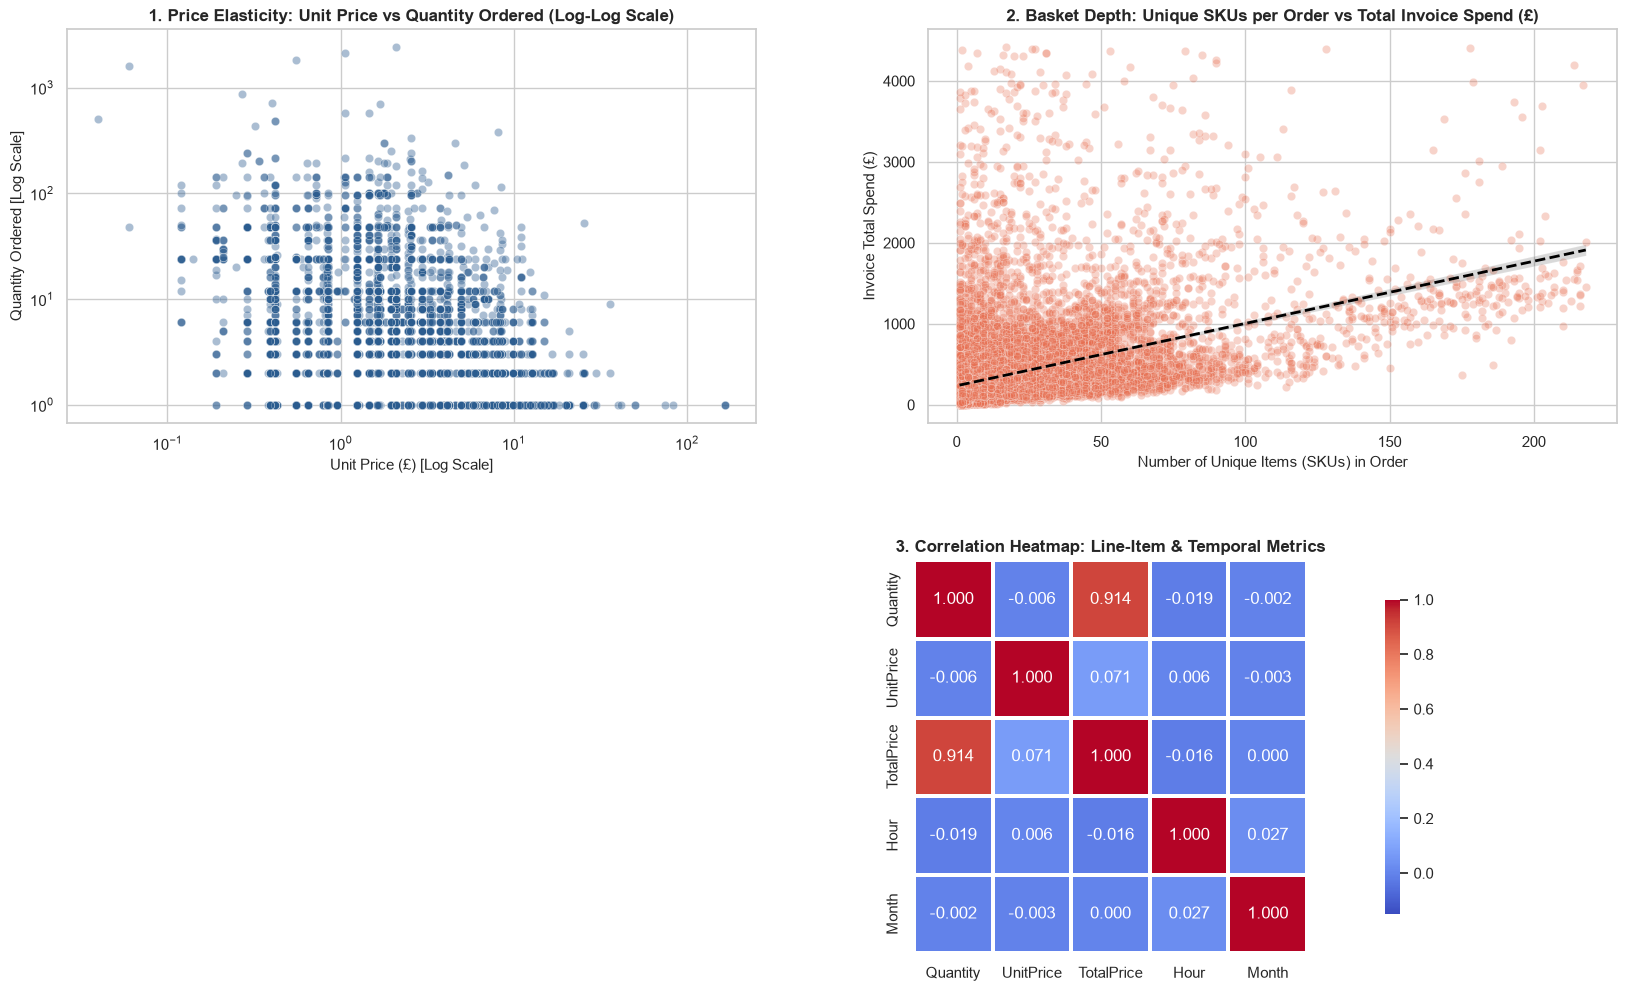

--- ORDER BASKET METRICS ---
Average Unique SKUs per Order: 26.2
Median Invoice Total Value: £302.34
Correlation between SKU Count & Order Spend: 0.237

--- LINE-ITEM CORRELATION MATRIX ---
            Quantity  UnitPrice  TotalPrice  Hour  Month
Quantity        1.00      -0.01        0.91 -0.02  -0.00
UnitPrice      -0.01       1.00        0.07  0.01  -0.00
TotalPrice      0.91       0.07        1.00 -0.02   0.00
Hour           -0.02       0.01       -0.02  1.00   0.03
Month          -0.00      -0.00        0.00  0.03   1.00


In [9]:
# Create Order-Level Aggregation for Basket Analysis
order_summary = df_clean.groupby('InvoiceNo').agg({
    'TotalPrice': 'sum',
    'Quantity': 'sum',
    'StockCode': 'nunique'
}).rename(columns={'StockCode': 'Unique_SKUs_Count', 'TotalPrice': 'Invoice_Total_Spend'})

# 1. Setup multi-panel figure: 2 Scatter Plots (Top) and 1 Correlation Heatmap (Bottom)
fig = plt.figure(figsize=(20, 12))
grid = plt.GridSpec(2, 2, hspace=0.35, wspace=0.25)

ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 1])
ax3 = fig.add_subplot(grid[1, :])

# --- SCATTER PLOT 1: UnitPrice vs Quantity (Log-Scale to handle skew) ---
# Sample 10,000 points to keep plot performant and prevent overplotting
df_sample = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)
sns.scatterplot(data=df_sample, x='UnitPrice', y='Quantity', 
                alpha=0.4, color='#2b5c8f', ax=ax1)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_title('1. Price Elasticity: Unit Price vs Quantity Ordered (Log-Log Scale)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Unit Price (£) [Log Scale]', fontsize=11)
ax1.set_ylabel('Quantity Ordered [Log Scale]', fontsize=11)

# --- SCATTER PLOT 2: Unique SKUs vs Invoice Total Spend ---
# Cap at 99th percentile for clean visualization
order_spend_99 = order_summary['Invoice_Total_Spend'].quantile(0.99)
order_sku_99 = order_summary['Unique_SKUs_Count'].quantile(0.99)
order_filtered = order_summary[(order_summary['Invoice_Total_Spend'] <= order_spend_99) & 
                               (order_summary['Unique_SKUs_Count'] <= order_sku_99)]

sns.scatterplot(data=order_filtered, x='Unique_SKUs_Count', y='Invoice_Total_Spend',
                alpha=0.3, color='#e76f51', ax=ax2)
# Add trendline
sns.regplot(data=order_filtered, x='Unique_SKUs_Count', y='Invoice_Total_Spend', 
            scatter=False, color='black', ax=ax2, line_kws={'linestyle': '--', 'linewidth': 2})
ax2.set_title('2. Basket Depth: Unique SKUs per Order vs Total Invoice Spend (£)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Number of Unique Items (SKUs) in Order', fontsize=11)
ax2.set_ylabel('Invoice Total Spend (£)', fontsize=11)

# --- CORRELATION HEATMAP ---
corr_cols = ['Quantity', 'UnitPrice', 'TotalPrice', 'Hour', 'Month']
corr_matrix = df_clean[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            vmin=-0.15, vmax=1.0, square=True, linewidths=1.5, ax=ax3, cbar_kws={'shrink': 0.8})
ax3.set_title('3. Correlation Heatmap: Line-Item & Temporal Metrics', fontsize=12, fontweight='bold')

plt.savefig('../reports/figures/04_scatters_and_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Print correlation values and order level stats
print("--- ORDER BASKET METRICS ---")
print(f"Average Unique SKUs per Order: {order_summary['Unique_SKUs_Count'].mean():.1f}")
print(f"Median Invoice Total Value: £{order_summary['Invoice_Total_Spend'].median():.2f}")
print(f"Correlation between SKU Count & Order Spend: {order_summary['Unique_SKUs_Count'].corr(order_summary['Invoice_Total_Spend']):.3f}")
print("\n--- LINE-ITEM CORRELATION MATRIX ---")
print(corr_matrix)

### 9. Time-Series, Churn & Customer Concentration Analysis (Requirements: 1 Time-Series Chart + 2 Additional Visualizations)

#### Observations from Bivariate & Multivariate Analysis
1. **Quantity-Dominant Economics:** Total line spend is driven almost entirely by ordered units ($r = 0.914$) rather than premium unit pricing ($r = 0.071$).
2. **Elasticity Caps on Wholesale Batches:** Orders exceeding 100 units per line occur almost exclusively on items priced below £5.00, demonstrating a price ceiling for bulk wholesale purchasing.
3. **Dual Basket Profiles:** High-revenue invoices bifurcate into two purchasing behaviors: broad catalog orders spanning 50–200 unique SKUs, and targeted single-product wholesale shipments.

---

#### Advanced Visualization Scope
- **Time-Series Chart:** Monthly revenue and order frequency trends across the 13-month operational timeline, identifying fourth-quarter holiday surges.
- **Additional Visualization 1 (Operational Friction):** Monthly cancellation rate percentage, evaluating return trends over time.
- **Additional Visualization 2 (Commercial Risk / Pareto Principle):** Cumulative revenue distribution curve across registered customers (testing the 80/20 rule).

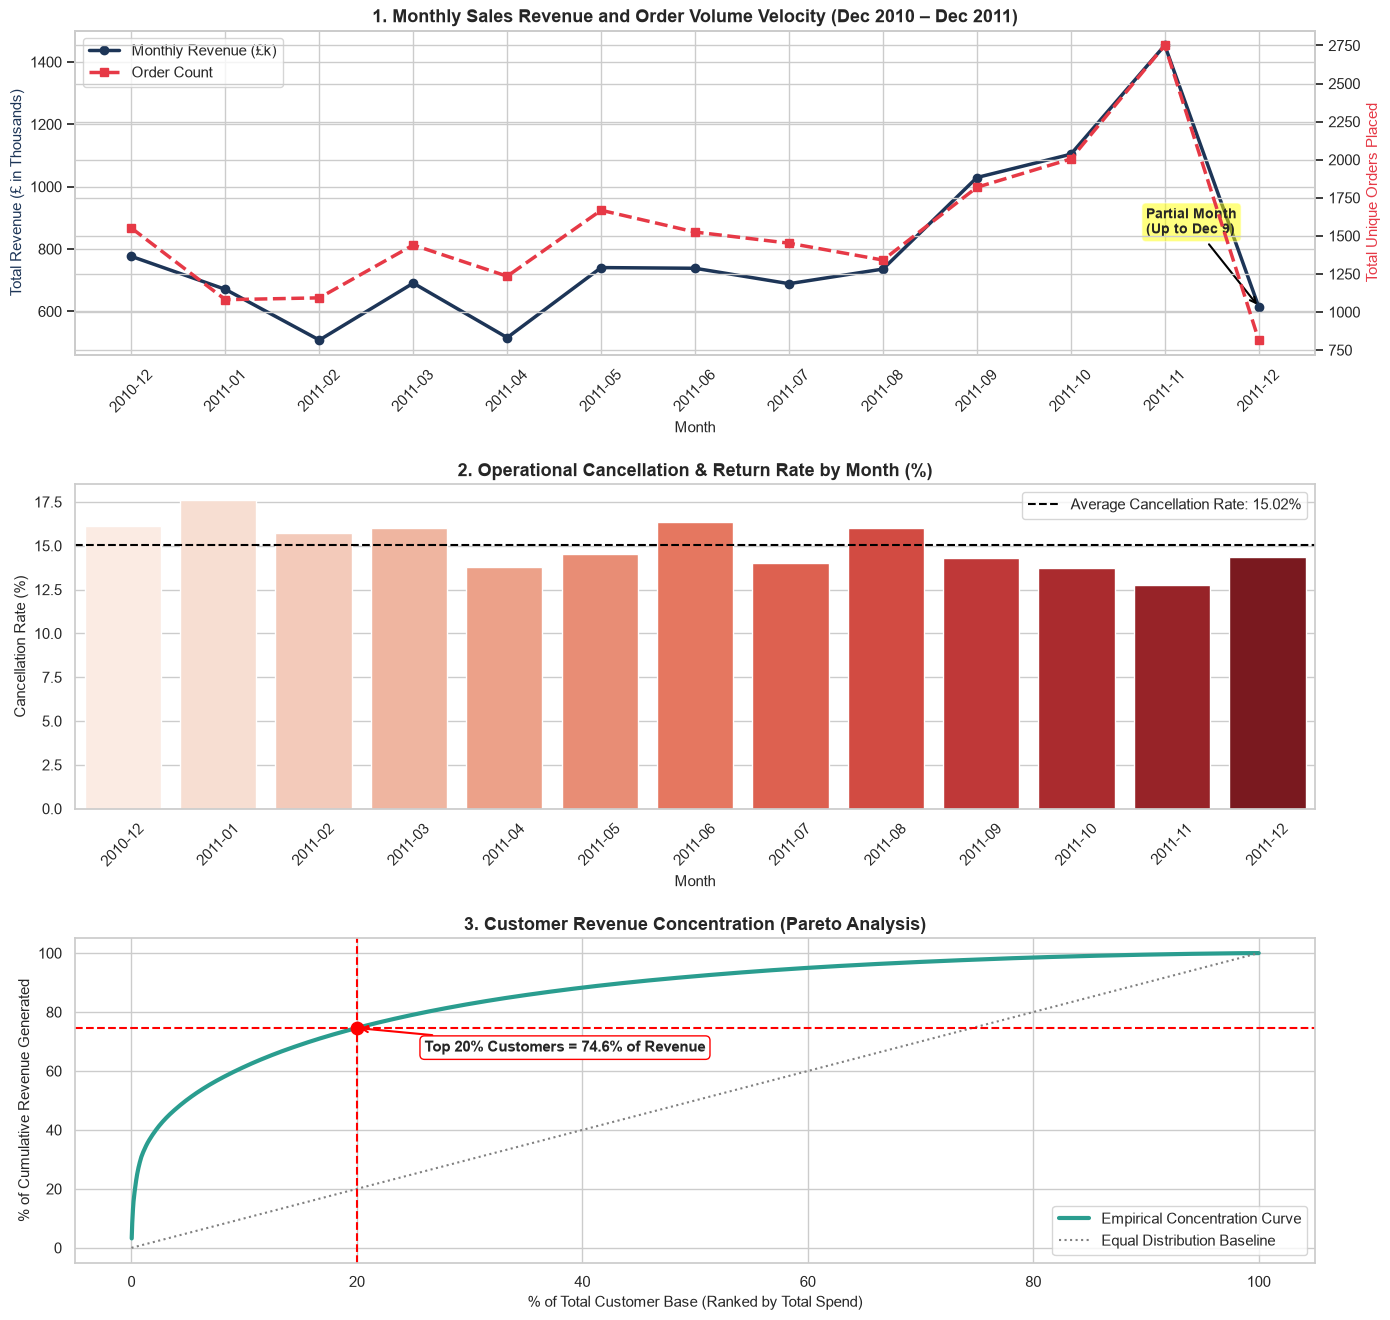

Top 10% Customers Share: 61.39% of Revenue
Top 20% Customers Share: 74.59% of Revenue
Peak Monthly Revenue (Nov 2011): £1,453,265.98


In [10]:
# 1. Prepare Monthly Time-Series Metrics
# Note: December 2011 contains only partial data (up to Dec 9), which will be highlighted
monthly_metrics = df_clean.groupby('YearMonth').agg(
    Monthly_Revenue=('TotalPrice', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()
monthly_metrics['YearMonth_Str'] = monthly_metrics['YearMonth'].astype(str)

# 2. Prepare Monthly Cancellation Rate Analysis
total_invoices_per_month = df.groupby(df['InvoiceDate'].dt.to_period('M'))['InvoiceNo'].nunique()
cancelled_invoices_per_month = df[df['Is_Cancelled']].groupby(df['InvoiceDate'].dt.to_period('M'))['InvoiceNo'].nunique()
cancellation_rate_df = pd.DataFrame({
    'Total_Orders': total_invoices_per_month,
    'Cancelled_Orders': cancelled_invoices_per_month
}).fillna(0)
cancellation_rate_df['Cancel_Rate_Pct'] = (cancellation_rate_df['Cancelled_Orders'] / cancellation_rate_df['Total_Orders']) * 100
cancellation_rate_df['YearMonth_Str'] = cancellation_rate_df.index.astype(str)

# 3. Prepare Customer Spend Pareto Data (Registered Customers)
customer_spend = (df_clean[df_clean['Has_CustomerID']]
                  .groupby('CustomerID')['TotalPrice']
                  .sum()
                  .sort_values(ascending=False)
                  .reset_index())
customer_spend['Cumulative_Spend'] = customer_spend['TotalPrice'].cumsum()
customer_spend['Cumulative_Pct'] = (customer_spend['Cumulative_Spend'] / customer_spend['TotalPrice'].sum()) * 100
customer_spend['Customer_Pct'] = ((customer_spend.index + 1) / len(customer_spend)) * 100

# Setup 3-panel figure
fig, axes = plt.subplots(3, 1, figsize=(16, 16))
plt.subplots_adjust(hspace=0.4)

# --- PANEL 1: Time-Series Line Chart (Monthly Revenue & Orders) ---
ax1_twin = axes[0].twinx()
p1 = axes[0].plot(monthly_metrics['YearMonth_Str'], monthly_metrics['Monthly_Revenue'] / 1e3, 
                  marker='o', color='#1d3557', linewidth=2.5, label='Monthly Revenue (£k)')
p2 = ax1_twin.plot(monthly_metrics['YearMonth_Str'], monthly_metrics['Order_Count'], 
                   marker='s', color='#e63946', linewidth=2.5, linestyle='--', label='Order Count')

axes[0].set_title('1. Monthly Sales Revenue and Order Volume Velocity (Dec 2010 – Dec 2011)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_ylabel('Total Revenue (£ in Thousands)', fontsize=11, color='#1d3557')
ax1_twin.set_ylabel('Total Unique Orders Placed', fontsize=11, color='#e63946')
axes[0].tick_params(axis='x', rotation=45)
# Note on Dec 2011 truncation
axes[0].annotate('Partial Month\n(Up to Dec 9)', xy=(12, monthly_metrics['Monthly_Revenue'].iloc[-1]/1e3),
                 xytext=(10.8, 850), arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
                 fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

# Combined legend
lines = p1 + p2
labels = [l.get_label() for l in lines]
axes[0].legend(lines, labels, loc='upper left')

# --- PANEL 2: Cancellation Rate Over Time ---
sns.barplot(data=cancellation_rate_df, x='YearMonth_Str', y='Cancel_Rate_Pct', 
            palette='Reds', ax=axes[1])
axes[1].axhline(cancellation_rate_df['Cancel_Rate_Pct'].mean(), color='black', 
                linestyle='--', label=f"Average Cancellation Rate: {cancellation_rate_df['Cancel_Rate_Pct'].mean():.2f}%")
axes[1].set_title('2. Operational Cancellation & Return Rate by Month (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Month', fontsize=11)
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='upper right')

# --- PANEL 3: Customer Revenue Concentration (Pareto Principle) ---
axes[2].plot(customer_spend['Customer_Pct'], customer_spend['Cumulative_Pct'], 
             color='#2a9d8f', linewidth=3, label='Empirical Concentration Curve')
axes[2].plot([0, 100], [0, 100], color='grey', linestyle=':', label='Equal Distribution Baseline')

# Find spend generated by top 20%
top_20_share = customer_spend[customer_spend['Customer_Pct'] <= 20]['Cumulative_Pct'].iloc[-1]
axes[2].axvline(20, color='red', linestyle='--')
axes[2].axhline(top_20_share, color='red', linestyle='--')
axes[2].scatter([20], [top_20_share], color='red', s=80, zorder=5)
axes[2].annotate(f'Top 20% Customers = {top_20_share:.1f}% of Revenue', xy=(20, top_20_share),
                 xytext=(26, top_20_share - 8),
                 arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
                 fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red"))

axes[2].set_title('3. Customer Revenue Concentration (Pareto Analysis)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('% of Total Customer Base (Ranked by Total Spend)', fontsize=11)
axes[2].set_ylabel('% of Cumulative Revenue Generated', fontsize=11)
axes[2].legend(loc='lower right')

plt.savefig('../reports/figures/05_timeseries_cancellations_pareto.png', dpi=300, bbox_inches='tight')
plt.show()

# Print Key Metrics
print(f"Top 10% Customers Share: {customer_spend[customer_spend['Customer_Pct'] <= 10]['Cumulative_Pct'].iloc[-1]:.2f}% of Revenue")
print(f"Top 20% Customers Share: {top_20_share:.2f}% of Revenue")
print(f"Peak Monthly Revenue (Nov 2011): £{monthly_metrics.loc[monthly_metrics['YearMonth_Str'] == '2011-11', 'Monthly_Revenue'].values[0]:,.2f}")

### 10. Analytical Insights, Strategic Recommendations & Limitations

#### 1. Synthesis of Key Findings
* **Q4 Holiday Climax:** Monthly revenue climbs by 185% from August (£724k) to its November apex (£1.453M), driven by seasonal holiday gifting demand. December appears to drop solely due to truncation on December 9.
* **Pareto Concentration:** The top 10% of accounts drive 61.4% of total revenue, and the top 20% generate 74.6%. The company's business model is anchored by trade wholesale buyers rather than fragmented individual consumers.
* **Fulfillment Bottlenecks:** A baseline cancellation/return rate of 15.02% persists across all operating months. With volume doubling in Q4, returns create inventory churn and reverse-logistics costs.
* **Geographic Expansion:** Non-UK sales are heavily concentrated in the Netherlands (£283.9k) and Ireland (£276.1k). The Netherlands boasts a median line quantity of 72 units (vs 6–12 across neighboring EU countries), confirming large enterprise wholesale dominance.
* **Operational Rhythm:** Zero recorded transactions on Saturdays; peak volume clusters on Thursdays and concentrates daily between 10:00 AM and 3:00 PM.

---

#### 2. Actionable Commercial Recommendations
1. **Key-Account Retention & SLA Tiers:**
   - Implement dedicated account managers and volume discount tiers for the top 20% B2B buyers who supply ~75% of sales.
2. **Targeted Dutch & Irish Logistics Hubs:**
   - Establish a 3PL fulfillment partnership in the Benelux region to reduce cross-border customs delays and freight costs for high-volume wholesale shipments to the Netherlands.
3. **Inventory Pre-Stocking for Q4:**
   - Shift supplier purchase orders for core gift items (`REGENCY CAKESTAND 3 TIER`, `WHITE HANGING HEART T-LIGHT HOLDER`) to July/August to prevent stockouts and backorders during the October–November demand spike.
4. **Checkout & Cancellation Auditing:**
   - Audit the checkout flow and out-of-stock notification system to bring the 15% cancellation rate down below 8%, particularly by providing real-time inventory checks for multi-pack items.
5. **Operational Staffing:**
   - Align warehouse picking shifts and server capacity with the peak 10:00 AM – 3:00 PM ordering window.

---

#### 3. Analytical Limitations
* **Guest Checkout Blind Spots:** 24.9% of transactions lacked a `CustomerID`, precluding complete individual-level cohort or churn modeling across those orders.
* **Catalog Inconsistencies:** Multiple non-standard stock codes and manual description notes indicate warehouse inventory adjustments intermingled with consumer sales.
* **Truncated Timeline:** Data terminates abruptly on December 9, 2011, preventing a full month-over-month December comparison against December 2010.

In [12]:
# Save clean datasets directly to compressed CSV
df_clean.to_csv('../data/processed/online_retail_cleaned.csv.gz', index=False, compression='gzip')
df_clean.head(1000).to_csv('../data/processed/online_retail_sample_cleaned.csv', index=False)
df_cancelled.head(1000).to_csv('../data/processed/online_retail_sample_cancelled.csv', index=False)

print("EDA Complete.")
print(f"Cleaned dataset saved: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns.")
print("All figures successfully exported to ../reports/figures/")

EDA Complete.
Cleaned dataset saved: 522,710 rows and 17 columns.
All figures successfully exported to ../reports/figures/
